# Legacy FEniCS dialect

Scripts written for the classic FEniCS (dolfin 2019) run on NGSolve after changing
`from fenics import *` (or `from dolfin import *`) into

```python
from ngsufl.fenics import *
```

This gives the dolfin style front end: `Expression` with C++ strings, boundary
functions `(x, on_boundary)`, `solve(a == L, u, bc)`, `errornorm`, `plot`, `File`.
Everything else is still UFL, translated to NGSolve.
Two classic programs from the FEniCS tutorial follow, then a table of the names.

## Poisson equation

$-\Delta u = f$ in the unit square, $u = u_D$ on the boundary, with the manufactured
solution $u_D = 1 + x^2 + 2y^2$ and $f = -6$.

In [1]:
from ngsufl.fenics import *
import matplotlib.pyplot as plt
import numpy as np

mesh = UnitSquareMesh(8, 8)
V = FunctionSpace(mesh, "P", 1)

u_D = Expression("1 + x[0]*x[0] + 2*x[1]*x[1]", degree=2)


def boundary(x, on_boundary):
    return on_boundary


bc = DirichletBC(V, u_D, boundary)

u = TrialFunction(V)
v = TestFunction(V)
f = Constant(-6.0)
a = dot(grad(u), grad(v)) * dx
L = f * v * dx

u = Function(V)
solve(a == L, u, bc)

The error in the $L^2$ norm, and at the vertices.  A piecewise linear function
cannot represent $u_D$, but the finite element solution is exact at the vertices.

In [2]:
print("error_L2  =", errornorm(u_D, u, "L2"))
vertex_values_u_D = u_D.compute_vertex_values(mesh)
vertex_values_u = u.compute_vertex_values(mesh)
print("error_max =", np.max(np.abs(vertex_values_u_D - vertex_values_u)))

error_L2  = 0.008235098073354905
error_max = 1.1102230246251565e-15


`plot` draws on the current matplotlib axes and returns the artist, so a colorbar is
added the usual way.  Meshes are drawn as wireframes.

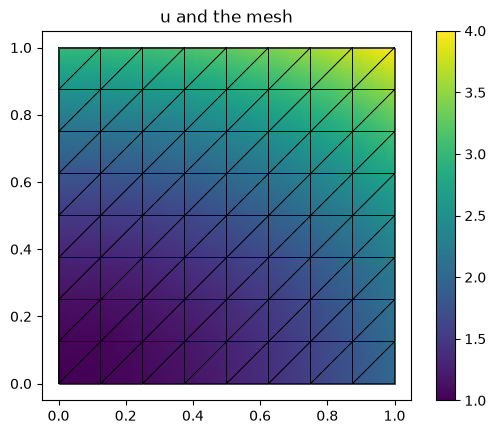

In [3]:
c = plot(u)
plt.colorbar(c)
plot(mesh)
plt.title("u and the mesh");

## The heat equation

$\partial_t u - \Delta u = f$ with backward Euler.  The exact solution
$1 + x^2 + \alpha y^2 + \beta t$ is also the boundary value.  Its time dependence is the
parameter `t` of the `Expression`: assigning `u_D.t = t` is all that is needed, the
boundary condition and the forms see the new value.

In [4]:
alpha, beta = 3.0, 1.2
mesh = UnitSquareMesh(10, 10)
V = FunctionSpace(mesh, "P", 1)

u_D = Expression("1 + x[0]*x[0] + alpha*x[1]*x[1] + beta*t", degree=2,
                 alpha=alpha, beta=beta, t=0)
bc = DirichletBC(V, u_D, boundary)

T, num_steps = 2.0, 10
dt = T / num_steps
u_n = interpolate(u_D, V)

u, v = TrialFunction(V), TestFunction(V)
f = Constant(beta - 2 - 2 * alpha)
F = u * v * dx + dt * dot(grad(u), grad(v)) * dx - (u_n + dt * f) * v * dx
a, L = lhs(F), rhs(F)

u = Function(V)
t = 0
for n in range(num_steps):
    t += dt
    u_D.t = t
    solve(a == L, u, bc)
    error = np.abs(u_D.compute_vertex_values(mesh) - u.compute_vertex_values(mesh)).max()
    u_n.assign(u)
print(f"t = {t:.1f}, max error at the vertices = {error:.2e}")

t = 2.0, max error at the vertices = 1.07e-14


Results are written the legacy way, a time series per `(u, t)` pair:

```python
vtkfile = File("heat/solution.pvd")
vtkfile << (u, t)
```

## Legacy name and what happens here

| legacy | here |
|---|---|
| `UnitSquareMesh`, `RectangleMesh`, `UnitCubeMesh`, `BoxMesh`, `IntervalMesh`, `Point` | structured NGSolve meshes, `diagonal="left"` or `"right"`; `mesh.coordinates()`, `cells()`, `hmax()` |
| `Expression("...", degree=2, a=1)` | the C++ string is parsed (operators, `pow`, `sqrt`, `exp`, ..., `?:`, `&&`, `near`); parameters are changed by attribute, the expression follows the mesh created last |
| `DirichletBC(V, g, sub_domain)` | `"on_boundary"`, C++ conditions, `SubDomain`, `CompiledSubDomain`, `AutoSubDomain` or a function `(x, on_boundary)`; a facet is constrained if all its vertices are marked; `method="pointwise"` pins vertices |
| `interpolate`, `u.interpolate` | nodal interpolation for Lagrange spaces |
| `solve(a == L, u, bc)`, `solve(F == 0, u, bc, J=J)` | NGSolve assembly and solvers, Newton with the `newton_solver` parameters |
| `linear_solver`: `lu`, `mumps`, `umfpack`, `superlu`, `petsc`, `default` | sparse direct solver |
| `linear_solver`: `cg`, `gmres`, `minres` | that Krylov method; `bicgstab`, `tfqmr` run as `gmres` |
| `preconditioner`: `none`, `jacobi`, `lu` | as named |
| `preconditioner`: `ilu`, `icc`, `sor`, `amg`, `hypre_amg`, `default` | Jacobi, there is no ILU |
| `assemble`, `bc.apply(A, b)`, `solve(A, u.vector(), b)`, `assemble_system`, `LUSolver`, `KrylovSolver` | work as in dolfin |
| `LinearVariationalSolver`, `NonlinearVariationalSolver` | with the nested auto-creating `.parameters`; `solve()` returns `(iterations, converged)` for Newton |
| `plot(obj)` | matplotlib on the current axes; meshes, scalar functions, vector fields (`mode="displacement"`, `mode="color"`) |
| `File("u.pvd") << u` | VTK output through NGSolve |
| `parameters`, `set_log_level`, `info` | accepted, mostly without effect |

Coefficient vectors (`u.vector()`) belong to NGSolve's hierarchical basis: they are
point values only for $P_1$ and $P_0$.  Use `compute_vertex_values` for point values.

**Not available** (a clear error says so): `MeshFunction` and `SubDomain.mark`,
`Measure(..., subdomain_data=...)`, `UserExpression` and `Expression` subclasses with
`eval`, `XDMFFile` / HDF5, `refine`, `mshr`, `TimeSeries`, periodic spaces
(`constrained_domain`), `vertex_to_dof_map`, mesh files, MPI.  The gradient of an
`Expression` inside a form is not translated either; interpolate it into a space first.